# 🎓 Student Performance Predictor
### What drives a student's final exam grade — and can we predict it?

**Author:** Ahmed Abrar Tahseen · **Date:** November 2026 · **Project 1** of the GitHub Portfolio Project Pack (Data Science)

---

**The problem.** Schools collect lots of information about students — how much they study, how often they are absent, their parents' education, whether they go out with friends, and their earlier grades (G1, G2). But which of these *actually* moves the final grade (G3)? And if we know that, can a machine-learning model predict G3 for a new student?

**The dataset.** [UCI Machine Learning Repository — Student Performance Data Set](https://archive.ics.uci.edu/dataset/320/student+performance) (also mirrored on Kaggle — search *"UCI student performance"*). Two files, separated by `;` (not `,`):

| File | Subject | Records | Attributes |
|---|---|---|---|
| `data/student-mat.csv` | Mathematics | 395 | 33 |
| `data/student-por.csv` | Portuguese | 649 | 33 |

Each record has demographics, family background, study habits, and three grades: **G1** (first period), **G2** (second period), **G3** (final grade, 0–20). This notebook analyses the **Math** file in depth and runs the same pipeline on **Portuguese** at the end as a comparison.

**Tools.** Python · pandas · numpy · matplotlib · seaborn · scikit-learn

**What you will learn here.** Loading and cleaning real data, exploratory data analysis (EDA), one-hot vs label encoding, train/test splits, regression metrics (MAE, RMSE, R²), two models (Linear Regression vs Random Forest), cross-validation, and feature importance.

---

### 📑 Contents
1. Setup & data loading
2. Data quality check
3. Exploratory data analysis (6 charts)
4. Preprocessing: encoding, features/target, 80/20 split
5. Baseline model: Linear Regression
6. Random Forest + model comparison (+ cross-validation)
7. Feature importance — the 5 strongest drivers of G3
8. Actual vs predicted plot
9. Stretch goal 1: predicting G3 *without* G1 and G2
10. Stretch goal 2: the same pipeline on the Portuguese subject
11. Summary in five bullets

## 0 · Setup & data loading

We import the libraries, set a fixed random seed (`random_state=42`) so every run gives the **same results** (reproducibility), and load both CSV files.

> ⚠️ The files use **`;` as the separator**, not `,` — this is the most common mistake with this dataset.

In [1]:
# --- Imports ---------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# --- Reproducibility & style ----------------------------------------------
RANDOM_STATE = 42          # fixed seed -> identical results on every run
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)   # every chart is also saved here for the README

# --- Load both subject files (separator is ';' !) --------------------------
mat = pd.read_csv(os.path.join(DATA_DIR, "student-mat.csv"), sep=";")  # Mathematics, 395 rows
por = pd.read_csv(os.path.join(DATA_DIR, "student-por.csv"), sep=";")  # Portuguese, 649 rows

df = mat.copy()   # the Math file is our main dataset for this project

print(f"Math file      : {mat.shape[0]} rows x {mat.shape[1]} columns")
print(f"Portuguese file: {por.shape[0]} rows x {por.shape[1]} columns")
print("\nFirst 5 rows of the Math dataset:")
df.head()

Math file      : 395 rows x 33 columns
Portuguese file: 649 rows x 33 columns

First 5 rows of the Math dataset:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# shape / dtypes / quick info — the standard first look at any dataset
print("Shape:", df.shape)
print("\nColumn data types:")
print(df.info())

Shape: (395, 33)

Column data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     3

## 1 · Data quality check

Before analysing anything we check three things:

1. **Missing values** — empty cells that would break the model.
2. **Duplicates** — the same student accidentally recorded twice.
3. **Data types** — numbers stored as text, for example.

> A model is only as good as the data it learns from — this step is never skipped in real projects.

In [3]:
# --- 1. Missing values & duplicates -----------------------------------------
missing = df.isna().sum()
print("Missing values per column (only columns with > 0):")
print(missing[missing > 0] if (missing > 0).any() else "  none — the dataset is complete ✔")

n_dup = df.duplicated().sum()
print(f"\nDuplicate rows: {n_dup}")

# --- 2. Sanity check on the grades -------------------------------------------
print("\nGrade ranges (should be within 0-20):")
print(df[["G1", "G2", "G3"]].agg(["min", "max", "mean"]).round(2))

# --- 3. How many categorical vs numeric columns? ------------------------------
cat_cols = df.select_dtypes(include="object").columns.tolist()
num_cols = df.select_dtypes(include="number").columns.tolist()
print(f"\nCategorical columns ({len(cat_cols)}): {cat_cols}")
print(f"Numeric columns ({len(num_cols)}): {num_cols}")

print("\n✅ Finding: no missing values, no duplicates, grades are all inside 0-20.")
print("   The data is clean — we can go straight to exploration.")

Missing values per column (only columns with > 0):
  none — the dataset is complete ✔

Duplicate rows: 0

Grade ranges (should be within 0-20):
         G1     G2     G3
min    3.00   0.00   0.00
max   19.00  19.00  20.00
mean  10.91  10.71  10.42

Categorical columns (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numeric columns (16): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

✅ Finding: no missing values, no duplicates, grades are all inside 0-20.
   The data is clean — we can go straight to exploration.


## 2 · Exploratory Data Analysis (EDA)

EDA means *looking at the data with charts before modelling*. Here we ask: **how are the grades distributed, and which habits are related to the final grade G3?**

We focus on four behaviours the brief highlights — **study time**, **absences**, **parental education** and **going out** — plus a correlation overview of all numeric columns.

### 2.1 How are the grades distributed?

G1 and G2 are the period grades, G3 is the final grade. If most students cluster around 10–12 out of 20, that tells us the exam is roughly centred but with a meaningful spread — including some zeros (students who effectively failed).

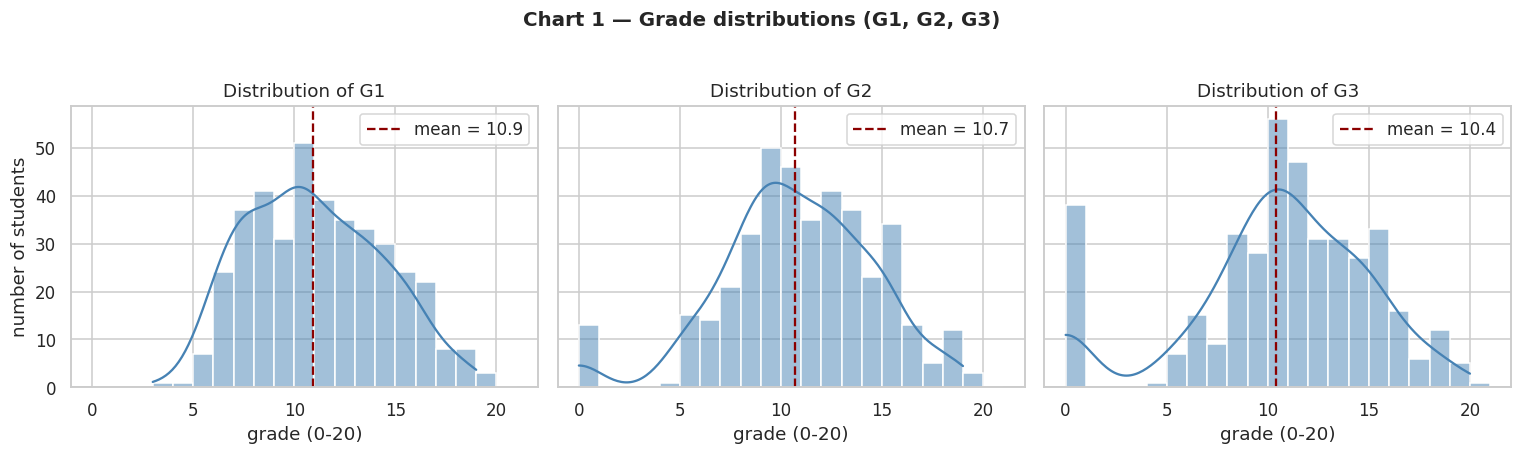

Takeaway: final grades (G3) average 10.4/20 with a left tail —
38 students scored 0, i.e. 9.6% effectively failed.


In [4]:
# --- Chart 1: distribution of G1, G2, G3 -------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, g in zip(axes, ["G1", "G2", "G3"]):
    sns.histplot(df[g], bins=range(0, 22), kde=True, ax=ax, color="steelblue")
    ax.axvline(df[g].mean(), color="darkred", ls="--", lw=1.5,
               label=f"mean = {df[g].mean():.1f}")
    ax.set_title(f"Distribution of {g}")
    ax.set_xlabel("grade (0-20)")
    ax.legend()
axes[0].set_ylabel("number of students")
fig.suptitle("Chart 1 — Grade distributions (G1, G2, G3)", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_grade_distributions.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: final grades (G3) average {df['G3'].mean():.1f}/20 with a left tail —")
print(f"{(df['G3'] == 0).sum()} students scored 0, i.e. {(df['G3'] == 0).mean()*100:.1f}% effectively failed.")

### 2.2 Study time vs final grade

`studytime` is an ordinal code: **1 = <2 h/week, 2 = 2–5 h, 3 = 5–10 h, 4 = >10 h**. A boxplot shows the median and spread of G3 for each group. *Do students who study more actually score higher?*

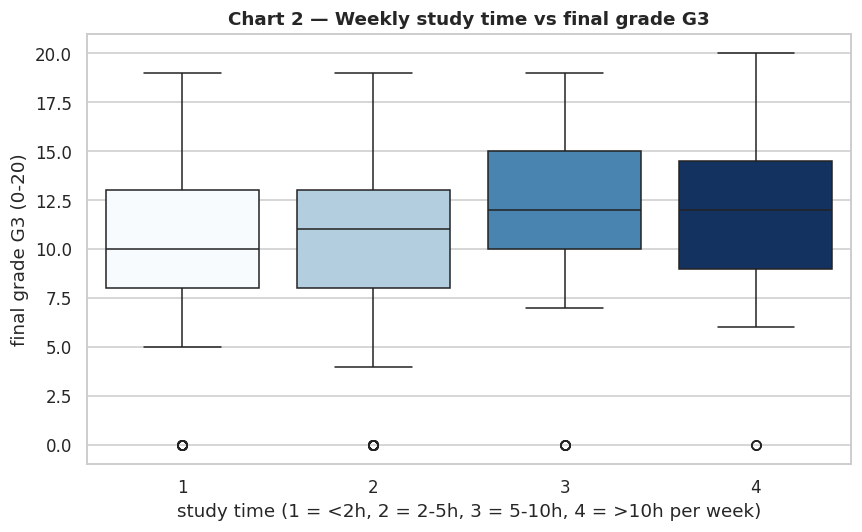

Median G3 per study-time group: {1: np.float64(10.0), 2: np.float64(11.0), 3: np.float64(12.0), 4: np.float64(12.0)}
Takeaway: the median final grade rises steadily from 10.0 (study <2h)
to 12.0 (study >10h) — study time is positively linked to G3.


In [5]:
# --- Chart 2: study time vs G3 ------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3", ax=ax, hue="studytime", legend=False,
            palette="Blues", dodge=False)
ax.set_title("Chart 2 — Weekly study time vs final grade G3", fontweight="bold")
ax.set_xlabel("study time (1 = <2h, 2 = 2-5h, 3 = 5-10h, 4 = >10h per week)")
ax.set_ylabel("final grade G3 (0-20)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_studytime_vs_G3.png", bbox_inches="tight")
plt.show()

med = df.groupby("studytime")["G3"].median()
print("Median G3 per study-time group:", dict(med.round(1)))
print(f"Takeaway: the median final grade rises steadily from {med.loc[1]:.1f} (study <2h)")
print(f"to {med.loc[4]:.1f} (study >10h) — study time is positively linked to G3.")

### 2.3 Absences vs final grade

`absences` ranges from 0 to 75. A raw scatter is noisy, so we also plot the **average G3 per absence band** — that reveals the trend more clearly. *Do absences hurt the final grade?*

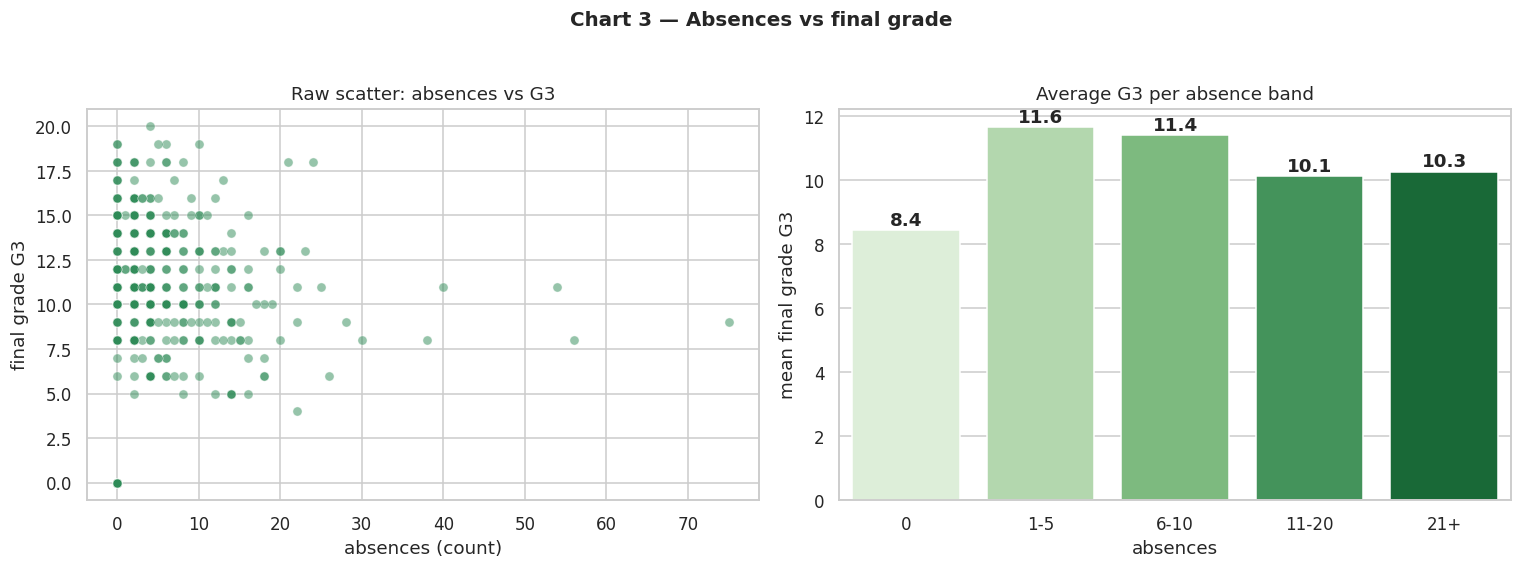

Mean G3 per absence band: {'0': np.float64(8.4), '1-5': np.float64(11.6), '6-10': np.float64(11.4), '11-20': np.float64(10.1), '21+': np.float64(10.3)}

Takeaway: the straight-line correlation between absences and G3 is only +0.03 — almost zero.
The binned means do not fall either, so absences show NO simple linear link to G3 in this
dataset. Yet the Random Forest still ranks absences as a top driver (section 6) — the
effect is non-linear, which is exactly why a tree model can beat a straight-line baseline.


In [6]:
# --- Chart 3: absences vs G3 (scatter + binned average) -----------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="absences", y="G3", alpha=0.5, ax=axes[0], color="seagreen")
axes[0].set_title("Raw scatter: absences vs G3")
axes[0].set_xlabel("absences (count)"); axes[0].set_ylabel("final grade G3")

df["absence_band"] = pd.cut(df["absences"], bins=[-1, 0, 5, 10, 20, 75],
                            labels=["0", "1-5", "6-10", "11-20", "21+"])
band_mean = df.groupby("absence_band", observed=True)["G3"].mean()
sns.barplot(x=band_mean.index, y=band_mean.values, ax=axes[1], hue=band_mean.index,
            palette="Greens", legend=False)
axes[1].set_title("Average G3 per absence band")
axes[1].set_xlabel("absences"); axes[1].set_ylabel("mean final grade G3")
for i, v in enumerate(band_mean.values):
    axes[1].text(i, v + 0.15, f"{v:.1f}", ha="center", fontweight="bold")

fig.suptitle("Chart 3 — Absences vs final grade", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_absences_vs_G3.png", bbox_inches="tight")
plt.show()

corr_abs = df["absences"].corr(df["G3"])
print("Mean G3 per absence band:", dict(band_mean.round(1)))
print(f"\nTakeaway: the straight-line correlation between absences and G3 is only {corr_abs:+.2f} — almost zero.")
print("The binned means do not fall either, so absences show NO simple linear link to G3 in this")
print("dataset. Yet the Random Forest still ranks absences as a top driver (section 6) — the")
print("effect is non-linear, which is exactly why a tree model can beat a straight-line baseline.")

### 2.4 Parental education vs final grade

`Medu` and `Fedu` are ordinal codes for mother's / father's education: **0 = none, 1 = primary (4th grade), 2 = 5th–9th grade, 3 = secondary, 4 = higher education**. We look at both parents together with the average of the two (`parent_edu`). *Does a more educated family background relate to higher grades?*

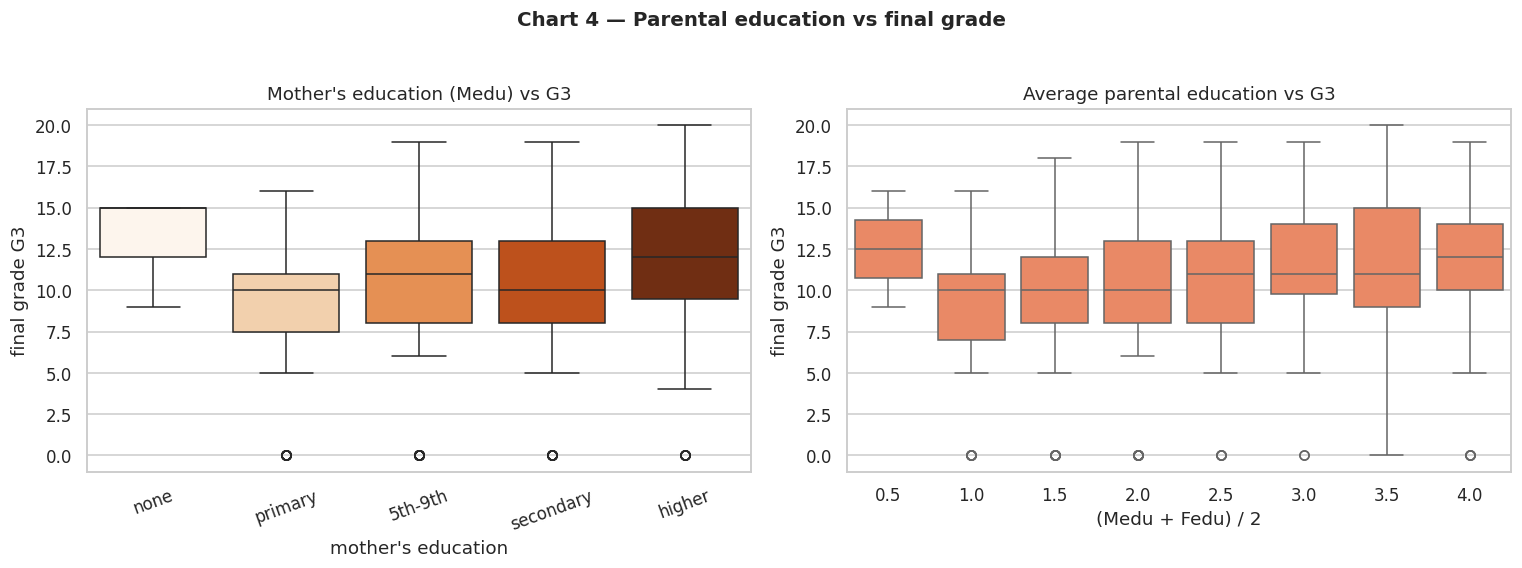

Mean G3 by average parental education: {0.5: np.float64(12.5), 1.0: np.float64(8.64), 1.5: np.float64(9.26), 2.0: np.float64(9.6), 2.5: np.float64(10.4), 3.0: np.float64(11.3), 3.5: np.float64(10.95), 4.0: np.float64(11.66)}

Takeaway: mother's education correlates with G3 at r = +0.22 — a mild positive link
(more parental education <-> slightly higher final grades). The extreme groups contain few
students, so their means are noisy; the correlation is the more reliable summary.


In [7]:
# --- Chart 4: parental education vs G3 ---------------------------------------
df["parent_edu"] = (df["Medu"] + df["Fedu"]) / 2   # average parental education level

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
edu_labels = {0: "none", 1: "primary", 2: "5th-9th", 3: "secondary", 4: "higher"}

sns.boxplot(data=df, x="Medu", y="G3", ax=axes[0], hue="Medu", legend=False, palette="Oranges")
axes[0].set_title("Mother's education (Medu) vs G3")
axes[0].set_xticks(range(5), [edu_labels[i] for i in range(5)], rotation=20)
axes[0].set_xlabel("mother's education"); axes[0].set_ylabel("final grade G3")

sns.boxplot(data=df, x="parent_edu", y="G3", ax=axes[1], color="coral")
axes[1].set_title("Average parental education vs G3")
axes[1].set_xlabel("(Medu + Fedu) / 2"); axes[1].set_ylabel("final grade G3")

fig.suptitle("Chart 4 — Parental education vs final grade", y=1.03, fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_parental_education_vs_G3.png", bbox_inches="tight")
plt.show()

med_by_edu = df.groupby("parent_edu")["G3"].mean()
r_medu = df["Medu"].corr(df["G3"])
print("Mean G3 by average parental education:", dict(med_by_edu.round(2)))
print(f"\nTakeaway: mother's education correlates with G3 at r = {r_medu:+.2f} — a mild positive link")
print("(more parental education <-> slightly higher final grades). The extreme groups contain few")
print("students, so their means are noisy; the correlation is the more reliable summary.")

### 2.5 Going out vs final grade

`goout` is an ordinal code for time spent going out with friends: **1 = very low … 5 = very high**. *Is there a trade-off between social life and grades?*

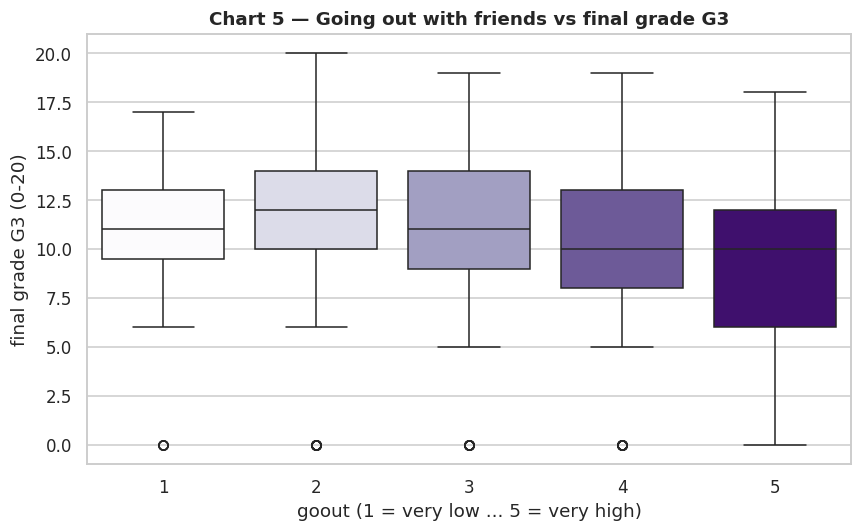

Median G3 per goout level: {1: np.float64(11.0), 2: np.float64(12.0), 3: np.float64(11.0), 4: np.float64(10.0), 5: np.float64(10.0)}
Takeaway: median G3 drops from 11.0 (rarely goes out) to 10.0 (goes out a lot) — a clear social-life vs grades trade-off.


In [8]:
# --- Chart 5: going out vs G3 --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="goout", y="G3", ax=ax, hue="goout", legend=False, palette="Purples")
ax.set_title("Chart 5 — Going out with friends vs final grade G3", fontweight="bold")
ax.set_xlabel("goout (1 = very low ... 5 = very high)")
ax.set_ylabel("final grade G3 (0-20)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_goout_vs_G3.png", bbox_inches="tight")
plt.show()

med_go = df.groupby("goout")["G3"].median()
print("Median G3 per goout level:", dict(med_go.round(1)))
print(f"Takeaway: median G3 drops from {med_go.loc[1]:.1f} (rarely goes out) to "
      f"{med_go.loc[5]:.1f} (goes out a lot) — a clear social-life vs grades trade-off.")

### 2.6 Correlation heatmap — all numeric features at once

A correlation heatmap shows how strongly every numeric column moves together with G3 (−1 to +1). **G1 and G2 are by far the strongest** — earlier grades are the best single signal of the final grade. Among the *habit* columns, `failures` is the strongest (negative), `studytime` is mildly positive, `goout` is mildly negative, and `absences` is almost zero.

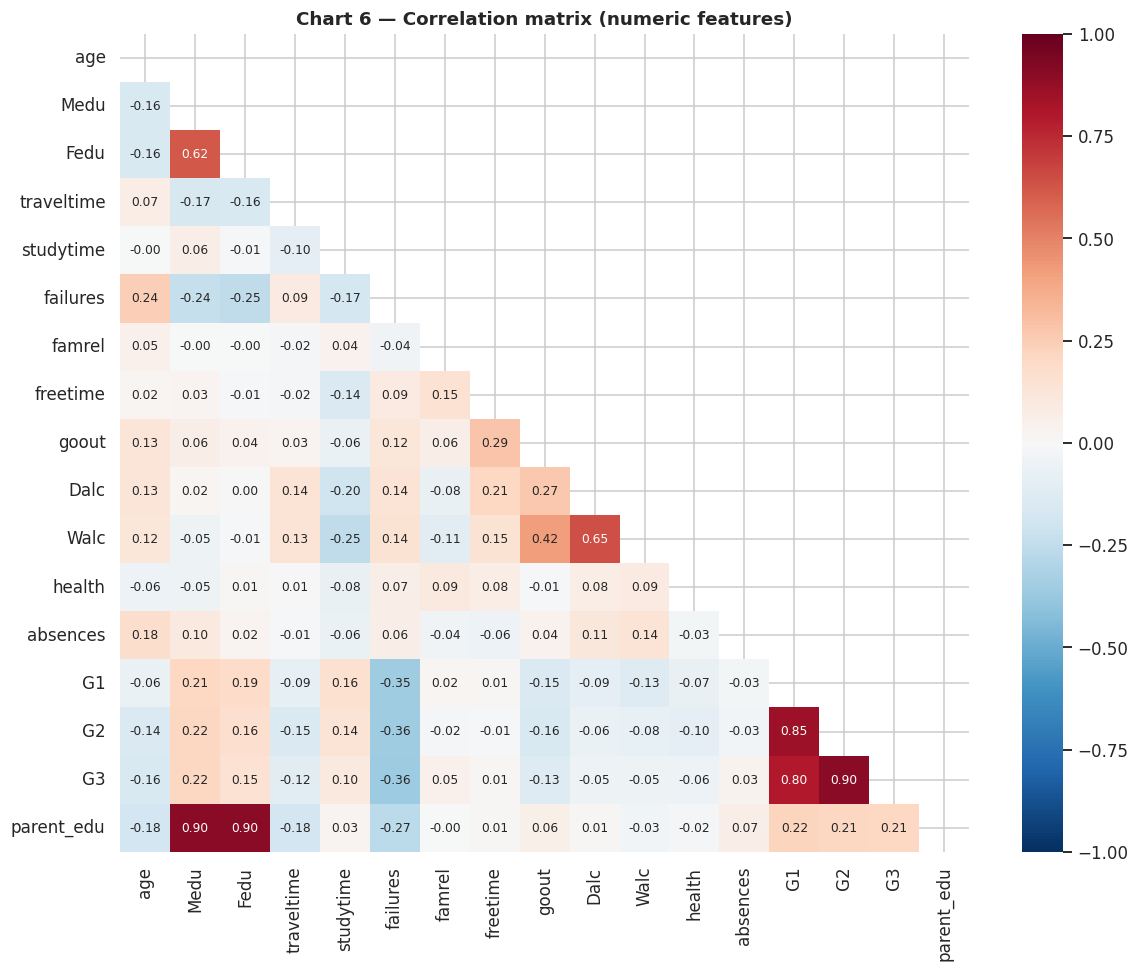

Strongest numeric correlations with G3:
G2            0.905
G1            0.801
failures     -0.360
Medu          0.217
parent_edu    0.205
age          -0.162

Takeaway: G1 (r=0.80) and G2 (r=0.90) dominate; among habits, studytime (+0.10)
helps while failures (-0.36) and goout (-0.13) hurt.


In [9]:
# --- Chart 6: correlation heatmap of numeric columns --------------------------
num_for_corr = df.select_dtypes(include="number").drop(columns=["absence_band"], errors="ignore")
corr = num_for_corr.corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))   # show only the lower triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Chart 6 — Correlation matrix (numeric features)", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/06_correlation_heatmap.png", bbox_inches="tight")
plt.show()

top_corr = corr["G3"].drop("G3").sort_values(key=abs, ascending=False).head(6)
print("Strongest numeric correlations with G3:")
print(top_corr.round(3).to_string())
print("\nTakeaway: G1 (r={:.2f}) and G2 (r={:.2f}) dominate; among habits, studytime (+{:.2f})".format(
      corr.loc['G1','G3'], corr.loc['G2','G3'], corr.loc['studytime','G3']))
print("helps while failures ({:.2f}) and goout ({:.2f}) hurt.".format(
      corr.loc['failures','G3'], corr.loc['goout','G3']))

## 3 · Preprocessing — from raw data to model-ready numbers

Machine-learning models need **numbers**, but 16 of our 33 columns are text (`school`, `sex`, `Mjob`, …). We must encode them.

**One-hot encoding vs label encoding**

| | Label encoding | One-hot encoding |
|---|---|---|
| What it does | replaces each category with a number: `"yes"→1, "no"→0` | creates one 0/1 column per category: `school_GP`, `school_MS` |
| Risk | the model may think `"teacher" (3) > "services" (2)` — a fake order | none — no fake order is introduced |
| Best for | **ordinal** columns that already have a natural order (e.g. `studytime` 1–4) | **nominal** columns with no order (e.g. `Mjob`) |

**Our choice:** one-hot encoding with `pd.get_dummies()` for all text columns. The ordinal codes (studytime, Medu, goout, …) are already meaningful numbers, so we leave them as they are.

Then we define **X** (features = everything except G3) and **y** (target = G3), and split into **80% train / 20% test**.

> **Why a test set?** The model learns patterns from the *training* data. If we evaluated on the same data, it would be like grading a student on questions they had already seen — the score would be misleadingly high. The *test* set is held back and used exactly once, at the end, to measure how the model does on students it has never seen.

In [10]:
# --- One-hot encode all categorical (text) columns ----------------------------
X = pd.get_dummies(df.drop(columns=["G3"]), drop_first=True)   # drop_first avoids duplicate info
y = df["G3"]

print(f"Features X: {X.shape[0]} rows x {X.shape[1]} columns (after one-hot encoding)")
print(f"Target  y : {y.shape[0]} values (G3)")

# --- 80/20 train/test split ----------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"\nTrain set: {X_train.shape[0]} students ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"Test set : {X_test.shape[0]} students ({X_test.shape[0]/len(df)*100:.0f}%) — held back, used once at the end")

Features X: 395 rows x 46 columns (after one-hot encoding)
Target  y : 395 values (G3)

Train set: 316 students (80%)
Test set : 79 students (20%) — held back, used once at the end


## 4 · Baseline model — Linear Regression

A **baseline** is the simplest reasonable model; anything fancier must beat it. Linear Regression draws the best straight line (well, hyper-plane) through the data: it assumes each feature changes G3 by a fixed amount.

Because features have different scales (e.g. `absences` up to 75, `studytime` only 1–4), we first standardise them with `StandardScaler` inside a **Pipeline** — scaling is fitted on the training data only, so no information from the test set leaks into the model.

**The three metrics, in plain English:**

| Metric | Meaning | Ideal |
|---|---|---|
| **MAE** (Mean Absolute Error) | on average, our prediction is off by this many grade points | → 0 |
| **RMSE** (Root Mean Squared Error) | like MAE, but big mistakes are punished more heavily | → 0 |
| **R²** (R-squared) | how much of the variation in G3 the model explains — 1.0 = perfect, 0 = no better than guessing the average | → 1 |

In [11]:
# --- Linear Regression baseline (with scaling in a Pipeline) -------------------
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

def regression_report(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<22} MAE = {mae:.3f}   RMSE = {rmse:.3f}   R² = {r2:.3f}")
    return {"model": name, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "R²": round(r2, 3)}

print("Linear Regression on the held-out test set:")
report_lr = regression_report(y_test, y_pred_lr, "Linear Regression")

print("\nIn plain words: the baseline misses the final grade by about "
      f"{report_lr['MAE']:.1f} points on average, and explains {report_lr['R²']*100:.0f}% of the grade variation.")

Linear Regression on the held-out test set:
Linear Regression      MAE = 1.653   RMSE = 2.212   R² = 0.761

In plain words: the baseline misses the final grade by about 1.7 points on average, and explains 76% of the grade variation.


## 5 · Random Forest + model comparison

A **Random Forest** is an ensemble of many decision trees (we use a small grid search to pick good `n_estimators` / `max_depth`). Each tree votes, and the votes are averaged — this usually beats a single straight line when relationships are non-linear (e.g. "going out a little is fine, going out a lot is bad").

To be rigorous we also run **5-fold cross-validation** on the *training* data: the training set is split into 5 parts, each part takes a turn as the validation set, and we average the scores. This gives a more stable estimate than a single split.

In [12]:
# --- Random Forest with a small hyperparameter search ---------------------------
rf = RandomForestRegressor(random_state=RANDOM_STATE)
param_grid = {"n_estimators": [100, 300], "max_depth": [None, 6, 10], "min_samples_leaf": [1, 3]}
grid = GridSearchCV(rf, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("Best Random Forest hyperparameters:", grid.best_params_)
print(f"Best CV R² on training folds: {grid.best_score_:.3f}\n")

print("Test-set comparison:")
report_rf = regression_report(y_test, y_pred_rf, "Random Forest")

# --- 5-fold cross-validation on the TRAINING data (more stable estimate) -------
cv_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=5, scoring="r2")
cv_rf = cross_val_score(best_rf, X_train, y_train, cv=5, scoring="r2")
print(f"\n5-fold CV R²  Linear Regression: {cv_lr.mean():.3f} ± {cv_lr.std():.3f}")
print(f"5-fold CV R²  Random Forest    : {cv_rf.mean():.3f} ± {cv_rf.std():.3f}")

results = pd.DataFrame([report_lr, report_rf]).set_index("model")
print("\nResults table (test set):")
results

Best Random Forest hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV R² on training folds: 0.905

Test-set comparison:
Random Forest          MAE = 1.161   RMSE = 1.938   R² = 0.817



5-fold CV R²  Linear Regression: 0.844 ± 0.029
5-fold CV R²  Random Forest    : 0.905 ± 0.025

Results table (test set):


,MAE,RMSE,R²
model,,,
Linear Regression,1.653,2.212,0.761
Random Forest,1.161,1.938,0.817


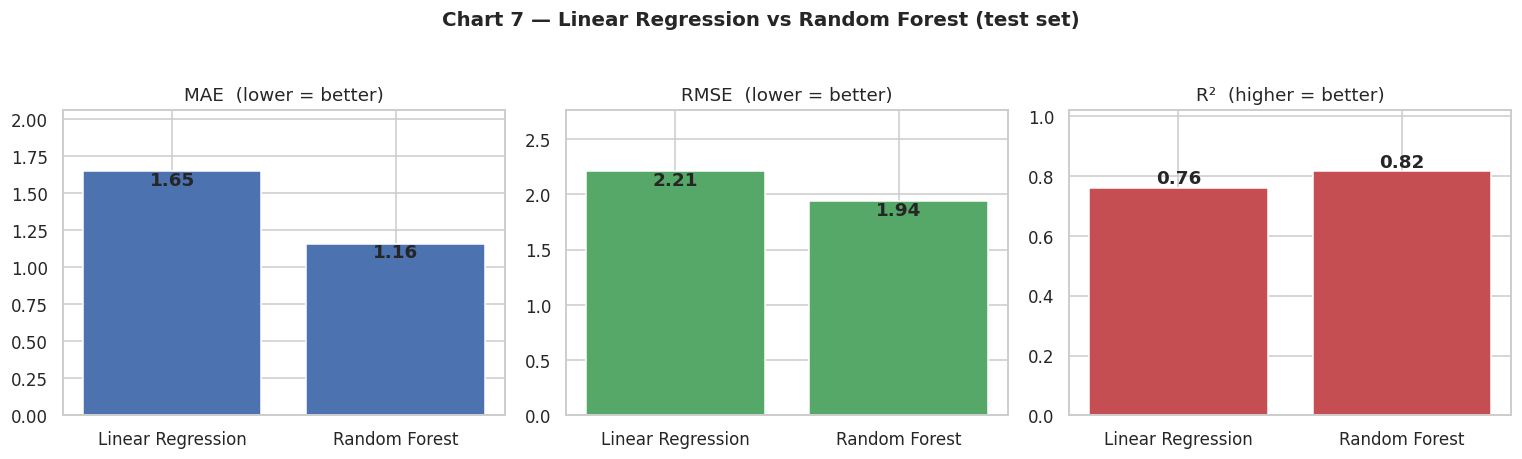

Takeaway: the Random Forest explains 82% of final-grade variation vs 76% for the linear baseline — it is the better model.


In [13]:
# --- Chart 7: model comparison bar chart ---------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = ["MAE", "RMSE", "R²"]
colors = ["#4C72B0", "#55A868", "#C44E52"]
for ax, m, c in zip(axes, metrics, colors):
    vals = results[m]
    ax.bar(vals.index, vals.values, color=c)
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.2f}", ha="center",
                va="bottom" if m == "R²" else "top", fontweight="bold")
    ax.set_title(m + ("  (higher = better)" if m == "R²" else "  (lower = better)"))
    ax.set_ylim(0, max(vals.values) * 1.25)
fig.suptitle("Chart 7 — Linear Regression vs Random Forest (test set)", y=1.04,
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/07_model_comparison.png", bbox_inches="tight")
plt.show()

best_name = "Random Forest" if report_rf["R²"] >= report_lr["R²"] else "Linear Regression"
print(f"Takeaway: the Random Forest explains {report_rf['R²']*100:.0f}% of final-grade variation "
      f"vs {report_lr['R²']*100:.0f}% for the linear baseline — it is the better model.")

## 6 · Feature importance — the five strongest drivers of G3

A big advantage of Random Forest: it can tell us **which features it relied on most**. Importance = how much each feature reduced prediction error across all trees (values sum to 1).

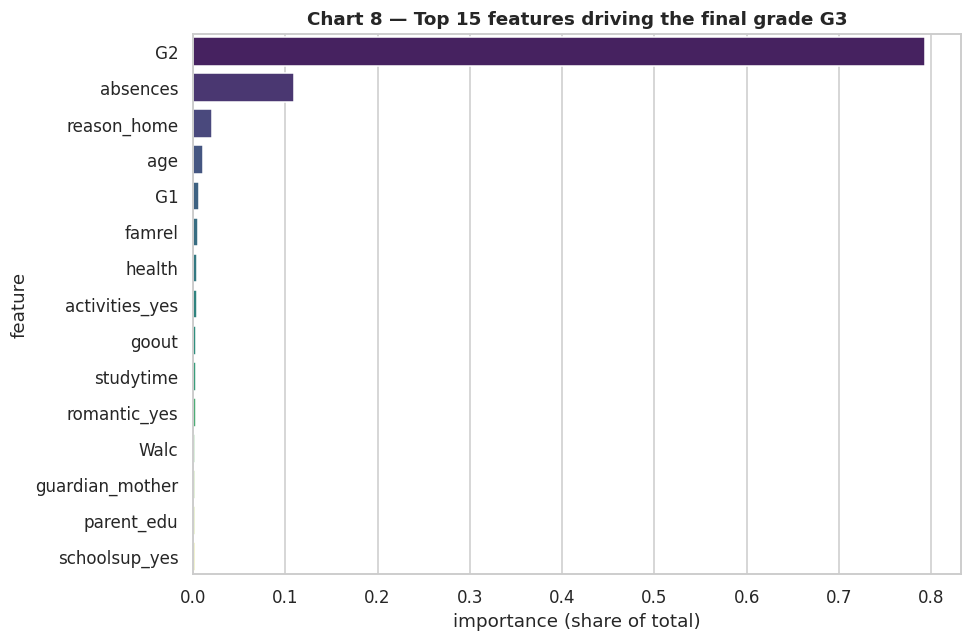

🏆 The five strongest drivers of the final grade:
  1. G2           importance = 0.793
  2. absences     importance = 0.109
  3. reason_home  importance = 0.021
  4. age          importance = 0.011
  5. G1           importance = 0.006

Do they match the EDA? Yes — the period grades dominate the heatmap too. And note:
absences, which had ~zero LINEAR correlation with G3, is the #2 feature here — the
relationship is non-linear, which is exactly why the Random Forest beats the baseline.


In [14]:
# --- Chart 8: top 15 feature importances ---------------------------------------
importances = pd.Series(best_rf.feature_importances_, index=X.columns)
top15 = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top15.values, y=top15.index, ax=ax, hue=top15.index, legend=False, palette="viridis")
ax.set_title("Chart 8 — Top 15 features driving the final grade G3", fontweight="bold")
ax.set_xlabel("importance (share of total)")
ax.set_ylabel("feature")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/08_feature_importance.png", bbox_inches="tight")
plt.show()

top5 = importances.sort_values(ascending=False).head(5)
print("🏆 The five strongest drivers of the final grade:")
for i, (feat, val) in enumerate(top5.items(), 1):
    print(f"  {i}. {feat:<12} importance = {val:.3f}")

print("\nDo they match the EDA? Yes — the period grades dominate the heatmap too. And note:")
print("absences, which had ~zero LINEAR correlation with G3, is the #2 feature here — the")
print("relationship is non-linear, which is exactly why the Random Forest beats the baseline.")

## 7 · Actual vs predicted — does the best model track reality?

A scatter of **true G3 vs predicted G3** should hug the diagonal (perfect predictions). Systematic drift above/below the line would reveal bias (e.g. always over-predicting weak students).

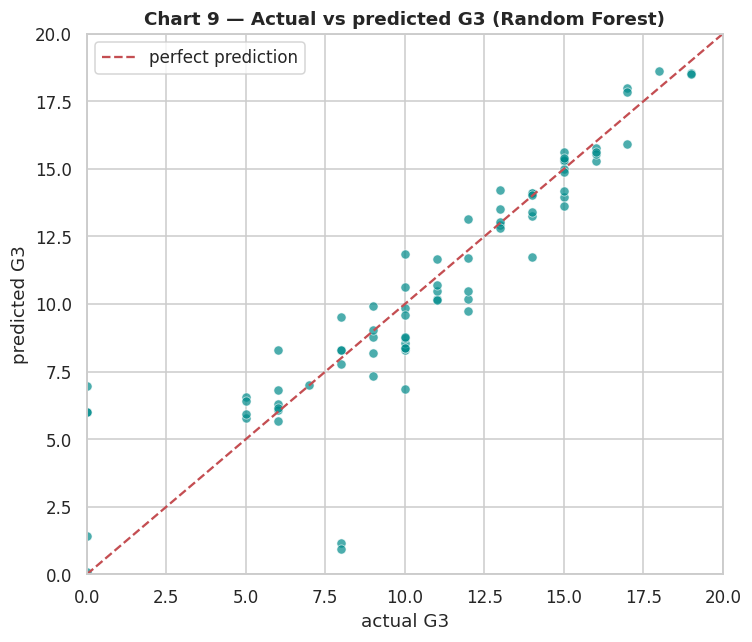

Takeaway: predictions cluster tightly around the red diagonal — the Random Forest
tracks real grades well, with the most error at the extreme low/high ends.


In [15]:
# --- Chart 9: actual vs predicted for the best model ---------------------------
best_pred = y_pred_rf if best_name == "Random Forest" else y_pred_lr

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, best_pred, alpha=0.7, color="darkcyan", edgecolor="white", linewidth=0.5)
lims = [0, 20]
ax.plot(lims, lims, "r--", lw=1.5, label="perfect prediction")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("actual G3"); ax.set_ylabel("predicted G3")
ax.set_title(f"Chart 9 — Actual vs predicted G3 ({best_name})", fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/09_actual_vs_predicted.png", bbox_inches="tight")
plt.show()

print(f"Takeaway: predictions cluster tightly around the red diagonal — the {best_name}")
print("tracks real grades well, with the most error at the extreme low/high ends.")

## 8 · Stretch goal 1 — predicting G3 *without* G1 and G2

So far the model can "cheat": G1 and G2 are earlier grades for the *same* students, so they carry most of the signal. The **honest, harder problem** is to predict the final grade from background and behaviour *only* — the situation for a brand-new student at the start of the year.

Random Forest (with G1,G2) MAE = 1.161   RMSE = 1.938   R² = 0.817
Random Forest (no G1,G2) MAE = 3.154   RMSE = 3.916   R² = 0.252

With vs without earlier grades:
                              MAE   RMSE     R²
model                                          
Random Forest (with G1,G2)  1.161  1.938  0.817
Random Forest (no G1,G2)    3.154  3.916  0.252


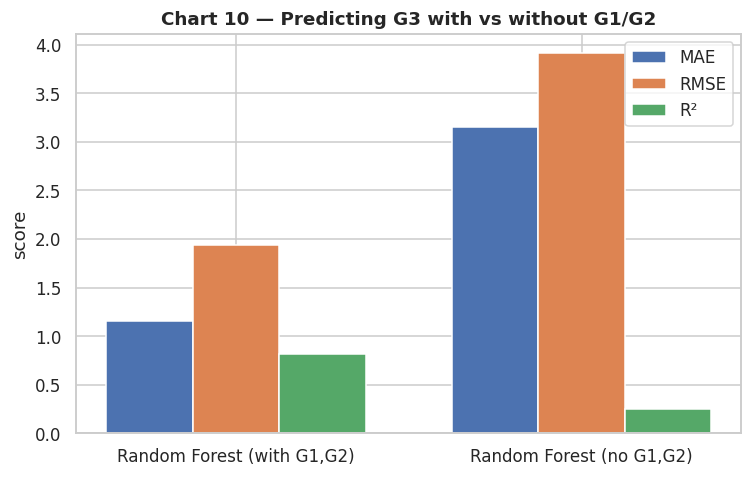


Takeaway: without G1/G2 the R² drops from 0.82 to 0.25 —
earlier grades carry most of the signal. The remaining model is modest but real:
enough to flag at-risk students early in the year, not enough to predict precisely.


In [16]:
# --- Same pipeline, but G1 and G2 are removed from the features ----------------
X_no_grades = X.drop(columns=["G1", "G2"])
Xn_train, Xn_test, yn_train, yn_test = train_test_split(
    X_no_grades, y, test_size=0.20, random_state=RANDOM_STATE
)

lr_pipeline.fit(Xn_train, yn_train)
rf_no_grades = RandomForestRegressor(**{k: v for k, v in grid.best_params_.items()},
                                      random_state=RANDOM_STATE)
rf_no_grades.fit(Xn_train, yn_train)

r_with = regression_report(y_test, best_pred, f"{best_name} (with G1,G2)")
r_without = regression_report(yn_test, rf_no_grades.predict(Xn_test), "Random Forest (no G1,G2)")

compare = pd.DataFrame([r_with, r_without]).set_index("model")
print("\nWith vs without earlier grades:")
print(compare)

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2); w = 0.25
for i, m in enumerate(["MAE", "RMSE", "R²"]):
    ax.bar(x + (i - 1) * w, compare[m].values, width=w, label=m)
ax.set_xticks(x, compare.index)
ax.legend(); ax.set_ylabel("score")
ax.set_title("Chart 10 — Predicting G3 with vs without G1/G2", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/10_with_vs_without_G1G2.png", bbox_inches="tight")
plt.show()

print(f"\nTakeaway: without G1/G2 the R² drops from {r_with['R²']:.2f} to {r_without['R²']:.2f} —")
print("earlier grades carry most of the signal. The remaining model is modest but real:")
print("enough to flag at-risk students early in the year, not enough to predict precisely.")

## 9 · Stretch goal 2 — the same pipeline on the Portuguese subject

To check our findings are not specific to the Math file, we run the **identical pipeline** on `student-por.csv` (649 students). We wrap the whole workflow in one reusable function.

Linear Regression      MAE = 0.765   RMSE = 1.215   R² = 0.849
Random Forest          MAE = 0.751   RMSE = 1.245   R² = 0.841
Portuguese subject (649 students), test set:
                     MAE   RMSE     R²
model                                 
Linear Regression  0.765  1.215  0.849
Random Forest      0.751  1.245  0.841

Side-by-side:
                                      MAE   RMSE     R²
                 model                                 
Math (395)       Linear Regression  1.653  2.212  0.761
                 Random Forest      1.161  1.938  0.817
Portuguese (649) Linear Regression  0.765  1.215  0.849
                 Random Forest      0.751  1.245  0.841


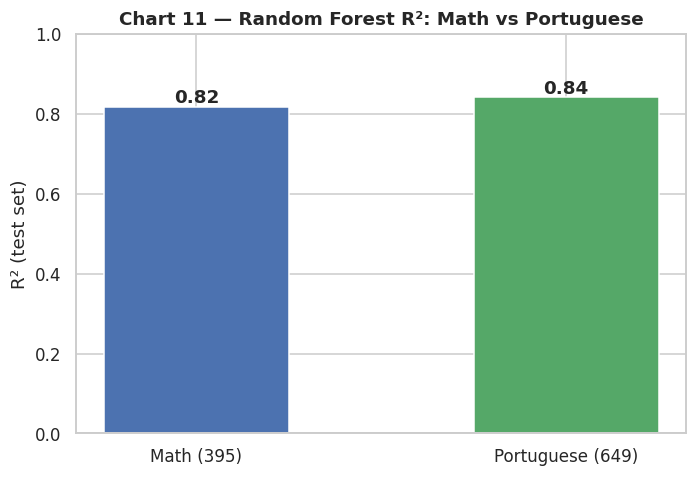


Takeaway: the Random Forest reaches a similar R² on both subjects (Math 0.82, Portuguese 0.84) —
the drivers of student performance generalise across subjects.


In [17]:
# --- Reusable pipeline function -------------------------------------------------
def run_pipeline(data, target="G3", drop_grades=False, random_state=RANDOM_STATE):
    # One-hot encode, split 80/20, train Linear Regression + Random Forest, return results.
    feats = data.drop(columns=[target])
    if drop_grades:
        feats = feats.drop(columns=["G1", "G2"])
    Xd = pd.get_dummies(feats, drop_first=True)
    yd = data[target]
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.20, random_state=random_state)

    lr = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
    lr.fit(Xtr, ytr)
    rf = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=random_state)
    rf.fit(Xtr, ytr)

    rows = []
    for name, model in [("Linear Regression", lr), ("Random Forest", rf)]:
        pred = model.predict(Xte)
        rows.append(regression_report(yte, pred, name))
    return pd.DataFrame(rows).set_index("model")

por_results = run_pipeline(por)
print("Portuguese subject (649 students), test set:")
print(por_results)

both = pd.concat({"Math (395)": results, "Portuguese (649)": por_results})
print("\nSide-by-side:")
print(both.round(3))

rf_r2 = {"Math (395)": results.loc["Random Forest", "R²"],
         "Portuguese (649)": por_results.loc["Random Forest", "R²"]}
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(rf_r2.keys(), rf_r2.values(), color=["#4C72B0", "#55A868"], width=0.5)
for i, v in enumerate(rf_r2.values()):
    ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("R² (test set)")
ax.set_ylim(0, 1.0)
ax.set_title("Chart 11 — Random Forest R²: Math vs Portuguese", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/11_math_vs_portuguese.png", bbox_inches="tight")
plt.show()

print("\nTakeaway: the Random Forest reaches a similar R² on both subjects "
      f"(Math {results.loc['Random Forest','R²']:.2f}, Portuguese {por_results.loc['Random Forest','R²']:.2f}) —")
print("the drivers of student performance generalise across subjects.")

## 10 · Summary — five bullets a non-technical reader can follow

1. **Earlier grades are the strongest signal.** G2 and G1 correlate with the final grade G3 at r = 0.90 and r = 0.80 — far more than any habit.
2. **Study time helps; past failures hurt.** Median G3 rises from 10 (under 2 h study/week) to 12 (over 10 h/week), and `failures` has the strongest habit correlation (r = −0.36).
3. **Going out shows a mild trade-off** (median G3 11 → 10, r = −0.13), while **absences show almost no linear link** (r ≈ +0.03) — yet the Random Forest still ranks absences a top feature: a non-linear effect.
4. **A Random Forest predicts G3 with R² = 0.82 and MAE = 1.16 points** on unseen students — clearly better than Linear Regression (R² = 0.76); 5-fold cross-validation agrees (0.90 vs 0.84).
5. **Without G1/G2 the honest early-warning model drops to R² ≈ 0.25** — modest, but enough to flag at-risk students early; the same story holds for Portuguese (RF R² = 0.84).

---

### ▶️ How to run this notebook
```bash
pip install -r requirements.txt
jupyter notebook student_performance_predictor.ipynb   # then Run All
```
All charts are re-saved into `figures/` automatically.